In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("Nassau Candy Distributor.csv")
print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
df.head()

Dataset loaded successfully!
Rows and columns: (10194, 18)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [13]:
financial_columns = ["Sales", "Units", "Gross Profit", "Cost"]
for col in financial_columns:df[col] = pd.to_numeric(df[col], errors="coerce")
print(df[financial_columns].isnull().sum())
print("\nFinancial summary:")
print(df[financial_columns].describe())


Sales           0
Units           0
Gross Profit    0
Cost            0
dtype: int64

Financial summary:
              Sales         Units  Gross Profit          Cost
count  10194.000000  10194.000000  10194.000000  10194.000000
mean      13.908537      3.791838      9.166451      4.742087
std       11.341020      2.228317      6.643740      5.061647
min        1.250000      1.000000      0.250000      0.600000
25%        7.200000      2.000000      4.900000      2.400000
50%       10.800000      3.000000      7.470000      3.600000
75%       18.000000      5.000000     12.250000      5.700000
max      260.000000     14.000000    130.000000    130.000000


In [14]:
df["Profit_Margin_Percent"] = np.where(df["Sales"] > 0,(df["Gross Profit"] / df["Sales"]) * 100,np.nan)
print(df[["Sales", "Gross Profit", "Cost","Profit_Margin_Percent"]].head(10))


   Sales  Gross Profit  Cost  Profit_Margin_Percent
0   6.50          4.22  2.28              64.923077
1   7.50          4.90  2.60              65.333333
2  10.47          7.47  3.00              71.346705
3  10.80          7.50  3.30              69.444444
4  11.25          7.35  3.90              65.333333
5  32.40         22.50  9.90              69.444444
6   7.50          4.90  2.60              65.333333
7   9.75          6.33  3.42              64.923077
8   6.98          4.98  2.00              71.346705
9  13.00          8.44  4.56              64.923077


In [15]:
product_analysis = (
    df.groupby("Product Name")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Gross Profit", "sum"),
          Total_Units=("Units", "sum"),
          Total_Cost=("Cost", "sum")
      )
      .sort_values("Total_Profit", ascending=False)
)

print("Top 10 products by gross profit:")
display(product_analysis.head(10))

Top 10 products by gross profit:


,Total_Sales,Total_Profit,Total_Units,Total_Cost
Product Name,,,,
Wonka Bar -Scrumdiddlyumptious,27874.80,19357.50,7743,8517.30
Wonka Bar - Triple Dazzle Caramel,28485.00,18610.20,7596,9874.80
Wonka Bar - Milk Chocolate,26867.75,17443.37,8267,9424.38
Wonka Bar - Nutty Crunch Surprise,23574.95,16819.95,6755,6755.00
Wonka Bar - Fudge Mallows,24890.40,16593.60,6914,8296.80
Lickable Wallpaper,7860.00,3930.00,393,3930.00
Wonka Gum,597.50,310.70,478,286.80
Everlasting Gobstopper,130.00,104.00,13,26.00
Kazookles,1205.75,92.75,371,1113.00


In [16]:
region_analysis = (
    df.groupby("Region")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Gross Profit", "sum"),
          Total_Units=("Units", "sum")
      )
      .sort_values("Total_Profit", ascending=False)
)

display(region_analysis)

,Total_Sales,Total_Profit,Total_Units
Region,,,
Pacific,46301.53,30485.94,12466
Atlantic,41197.24,26973.70,11159
Interior,32037.60,21282.49,8820
Gulf,22247.26,14700.67,6209


In [17]:
division_analysis = (
    df.groupby("Division")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Gross Profit", "sum"),
          Total_Units=("Units", "sum")
      )
      .sort_values("Total_Profit", ascending=False)
)

display(division_analysis)

,Total_Sales,Total_Profit,Total_Units
Division,,,
Chocolate,131692.90,88824.62,37275
Other,9663.25,4333.45,1242
Sugar,427.48,284.73,137


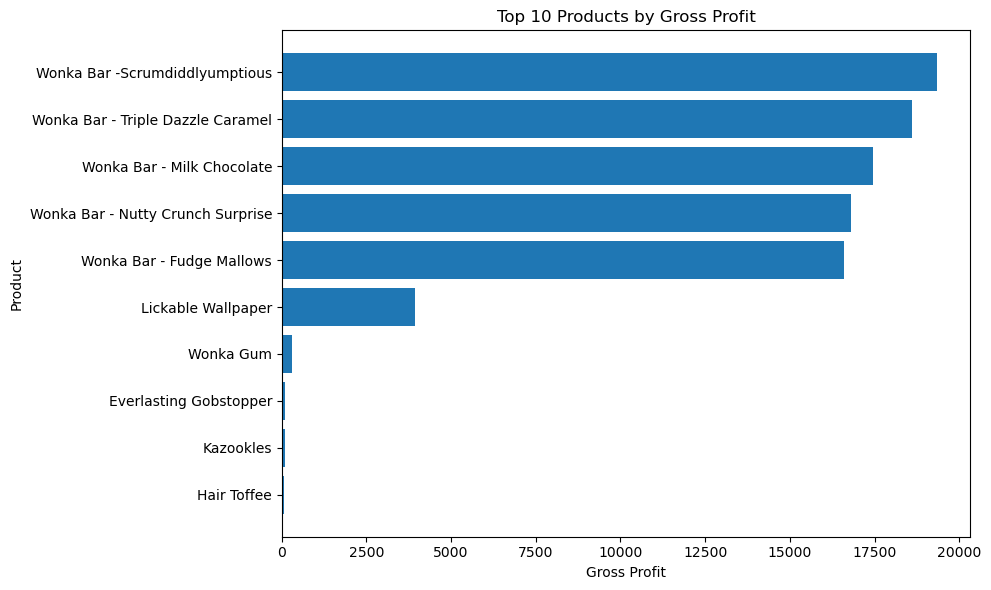

In [18]:
top_products = product_analysis.head(10).sort_values("Total_Profit")
plt.figure(figsize=(10, 6))
plt.barh(top_products.index, top_products["Total_Profit"])
plt.title("Top 10 Products by Gross Profit")
plt.xlabel("Gross Profit")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

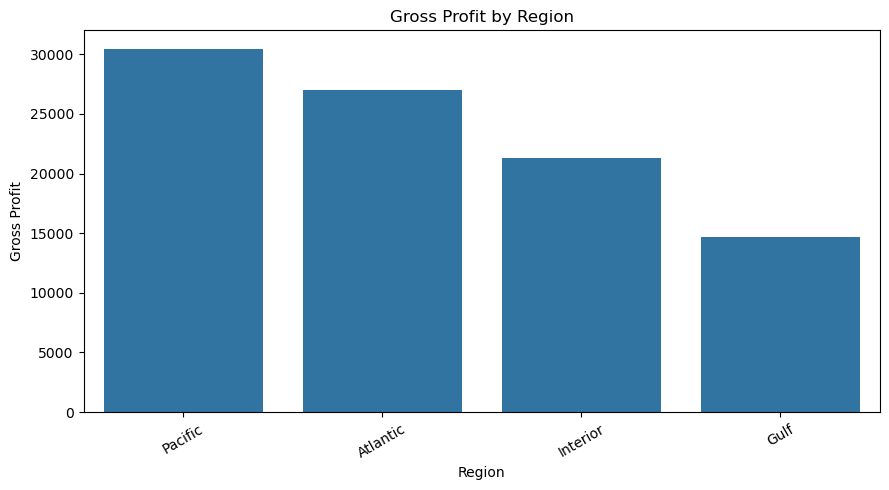

In [19]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=region_analysis.reset_index(),
    x="Region",
    y="Total_Profit")
plt.title("Gross Profit by Region")
plt.xlabel("Region")
plt.ylabel("Gross Profit")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [20]:
product_analysis.to_csv("product_profitability_analysis.csv")
region_analysis.to_csv("regional_profitability_analysis.csv")
division_analysis.to_csv("division_profitability_analysis.csv")
print("Analysis completed!")
print("Results saved successfully.")

Analysis completed!
Results saved successfully.
